Import libraries

In [1]:
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

import matplotlib.pyplot as plt

Check working directory

In [2]:
import os

print(os.getcwd())

d:\Study\2nd sem1\ML practicles\experiments


Load dataset

In [3]:
df = pd.read_csv("../datasets/house_price_dataset.csv")

X = df[['Area_sqft', 'Bedrooms', 'Bathrooms', 'Year_Built', 'Price']]

Handle missing values

In [3]:
imputer = SimpleImputer(strategy='median')

X = imputer.fit_transform(X)

Standardize the data

In [4]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

 Apply K-Means

In [5]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans.fit(X_scaled)

labels = kmeans.labels_

print("Cluster Labels:")
print(labels)

c:\Users\shiva\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\shiva\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\shiva\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\shiva\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

Cluster Labels:
[1 0 0 ... 0 1 0]


Check cluster centers

In [6]:
print("Cluster Centers:")
print(kmeans.cluster_centers_)

Cluster Centers:
[[ 8.06232813e-01  1.10369189e-01  2.31900543e-03  1.15657458e-02
   8.29425971e-01]
 [-6.85332318e-01 -9.35588651e-02 -4.35747619e-02 -9.98305221e-03
  -7.05033011e-01]
 [ 1.44848271e-01 -1.90935997e-01  3.37699843e+01  1.25192026e-01
   1.37259793e-01]]


Visualize clusters

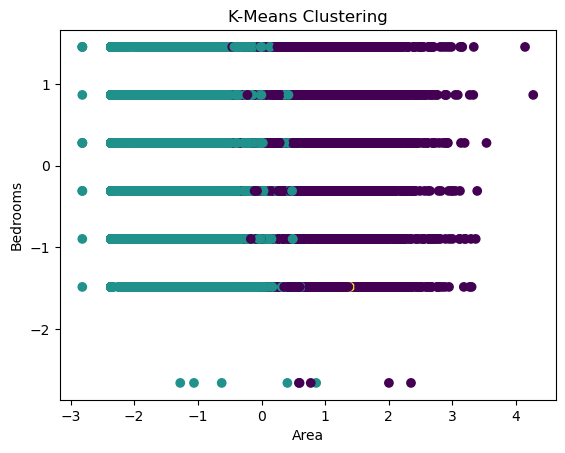

In [7]:
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels
)

plt.xlabel("Area")
plt.ylabel("Bedrooms")

plt.title("K-Means Clustering")

plt.show()

Calculate inertia

In [10]:
print("Inertia:", kmeans.inertia_)

Inertia: 46470.85046694536


Find the best K using the Elbow Method

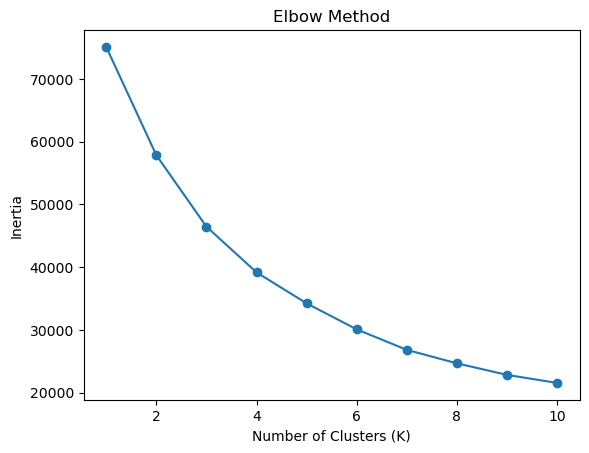

In [11]:
inertia = []

for k in range(1, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    inertia.append(model.inertia_)

plt.plot(range(1, 11), inertia, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.title("Elbow Method")

plt.show()